# TP 1 — Python, simulation et premières variables aléatoires

**Corrigé enseignant · Année universitaire 2026–2027 · Yiye Jiang**

Ce notebook suit **l'ordre et les questions de la feuille de TP1 corrigée**. Chaque réponse comprend, selon les besoins, une explication mathématique, un programme Python exécutable et sa sortie (tableau, valeur ou graphique). Les simulations utilisent une graine fixée pour rendre les résultats reproductibles.

**Utilisation :** ouvrir le fichier `.ipynb` dans Jupyter. Les sorties sont déjà enregistrées ; pour tout recalculer, choisir *Restart & Run All*. Bibliothèques utilisées : NumPy, Matplotlib, SciPy.

## Initialisation — bibliothèques et générateur aléatoire

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import quad

rng = np.random.default_rng(2026)

print("NumPy :", np.__version__)
print("Bibliothèques importées ; graine aléatoire : 2026")

NumPy : 2.3.5
Bibliothèques importées ; graine aléatoire : 2026


# 1. Remise à niveau Python orientée proba-stat

## Exercice 1 — Tableaux, tri, filtrage et indices

On travaille sur le tableau de dix observations de l'énoncé. Les positions Python commencent à **0** et non à 1.

In [2]:
x = np.array([12.4, 10.1, 9.8, 15.2, 11.7,
              13.3, 8.9, 12.4, 14.1, 10.7])
print("x =", x)

x = [12.4 10.1  9.8 15.2 11.7 13.3  8.9 12.4 14.1 10.7]


### 1.1 — Taille, type et extractions

In [3]:
print("Nombre d'éléments :", len(x))
print("Type de x :", type(x))
print("Trois premières valeurs :", x[:3])
print("Trois dernières valeurs :", x[-3:])
print("Une valeur sur deux :", x[::2])

Nombre d'éléments : 10
Type de x : <class 'numpy.ndarray'>
Trois premières valeurs : [12.4 10.1  9.8]
Trois dernières valeurs : [12.4 14.1 10.7]
Une valeur sur deux : [12.4  9.8 11.7  8.9 14.1]


La syntaxe `x[a:b:c]` sélectionne les indices à partir de `a` (inclus) jusqu'à `b` (exclu), avec un pas `c`. Les valeurs `x[::2]` correspondent ici aux indices 0, 2, 4, 6 et 8.

### 1.2 — Trier les valeurs et retrouver leurs indices

In [4]:
x_trie = np.sort(x)
indices_tri = np.argsort(x)
print("Valeurs triées :", x_trie)
print("Indices qui réalisent le tri :", indices_tri)
print("Vérification, x[indices_tri] :", x[indices_tri])

Valeurs triées : [ 8.9  9.8 10.1 10.7 11.7 12.4 12.4 13.3 14.1 15.2]
Indices qui réalisent le tri : [6 2 1 9 4 7 0 5 8 3]
Vérification, x[indices_tri] : [ 8.9  9.8 10.1 10.7 11.7 12.4 12.4 13.3 14.1 15.2]


`np.sort(x)` renvoie les valeurs triées ; `np.argsort(x)` renvoie la **permutation des indices** qui produit ce tri. Les deux occurrences de 12,4 sont conservées.

### 1.3 — Filtrer les observations telles que $10\le x_i\le13$

In [5]:
masque = (x >= 10) & (x <= 13)
valeurs = x[masque]
indices = np.where(masque)[0]
print("Masque booléen :", masque)
print("Valeurs retenues :", valeurs)
print("Indices dans x :", indices)

Masque booléen : [ True  True False False  True False False  True False  True]
Valeurs retenues : [12.4 10.1 11.7 12.4 10.7]
Indices dans x : [0 1 4 7 9]


Il faut mettre chaque comparaison entre parenthèses et utiliser `&` (ET terme à terme), et non le mot-clé Python `and`, qui ne fonctionne pas sur un tableau de booléens.

### 1.4 — Compter les observations vérifiant la condition

In [6]:
n_condition = np.sum(masque)
print("Nombre d'observations entre 10 et 13 inclus :", n_condition)

Nombre d'observations entre 10 et 13 inclus : 5


En NumPy, les booléens se somment : `True` compte pour 1 et `False` pour 0.

### 1.5 — Minimum, maximum et positions

In [7]:
i_max = np.argmax(x)
i_min = np.argmin(x)
print(f"Maximum : {x[i_max]} ; indice : {i_max}")
print(f"Minimum : {x[i_min]} ; indice : {i_min}")

Maximum : 15.2 ; indice : 3
Minimum : 8.9 ; indice : 6


`np.argmax` et `np.argmin` renvoient l’indice de la **première occurrence** si plusieurs observations atteignent le même optimum.

### 1.6 — Moyenne, médiane, écart-type et quantiles

In [8]:
print(f"Moyenne : {np.mean(x):.4f}")
print(f"Médiane : {np.median(x):.4f}")
print(f"Écart-type (ddof=0) : {np.std(x):.4f}")
ordres = np.array([0.25, 0.50, 0.75])
print("Quantiles (0.25, 0.50, 0.75) :", np.quantile(x, ordres))

Moyenne : 11.8600
Médiane : 12.0500
Écart-type (ddof=0) : 1.9054
Quantiles (0.25, 0.50, 0.75) : [10.25  12.05  13.075]


Par défaut, `np.quantile` interpole lorsque le quantile est situé entre deux observations triées. `np.median(x)` coïncide avec `np.quantile(x, 0.5)`.

### 1.7 — Comparer les deux conventions pour l’écart-type

In [9]:
s0 = np.std(x)
s1 = np.std(x, ddof=1)
print(f"np.std(x)         = {s0:.6f}")
print(f"np.std(x, ddof=1) = {s1:.6f}")
print("Rapport s1/s0 :", round(s1 / s0, 6))

np.std(x)         = 1.905361
np.std(x, ddof=1) = 2.008427
Rapport s1/s0 : 1.054093


La différence est le **dénominateur** de la variance empirique :

- `ddof=0` : $s_0^2=\frac1n\sum_{i=1}^n(x_i-\bar x)^2$ ;
- `ddof=1` : $s_1^2=\frac1{n-1}\sum_{i=1}^n(x_i-\bar x)^2$.

Le second est la version avec correction de Bessel, souvent utilisée pour estimer la variance d'une population à partir d'un échantillon.

## Exercice 2 — Matrices et opérations utiles pour la suite du module

In [10]:
t = np.array([0., 1., 2., 3., 4.])
y = np.array([2.1, 1.7, 1.1, 0.6, 0.2])
X = np.column_stack((np.ones(len(t)), t))

### 2.1 — Matrice, dimensions et transposée

In [11]:
print("X =\n", X)
print("Dimensions de X :", X.shape)
print("X.T =\n", X.T)

X =
 [[1. 0.]
 [1. 1.]
 [1. 2.]
 [1. 3.]
 [1. 4.]]
Dimensions de X : (5, 2)
X.T =
 [[1. 1. 1. 1. 1.]
 [0. 1. 2. 3. 4.]]


La matrice `X` comporte 5 lignes (observations) et 2 colonnes (constante et variable `t`). La transposée `X.T` est donc de taille 2 × 5.

### 2.2 — Calculer $X^{\top}X$ et $X^{\top}y$

In [12]:
G = X.T @ X
c = X.T @ y
print("X.T @ X =\n", G)
print("X.T @ y =", c)

X.T @ X =
 [[ 5. 10.]
 [10. 30.]]
X.T @ y = [5.7 6.5]


L'opérateur `@` réalise le **produit matriciel** ; il ne faut pas le confondre avec `*` sur des tableaux NumPy.

### 2.3 — Produit terme à terme et produit matriciel

In [13]:
A = np.array([[1., 2.], [3., 4.]])
B = np.array([[2., 0.], [1., 2.]])
print("A * B =\n", A * B)
print("np.multiply(A, B) =\n", np.multiply(A, B))
print("A @ B =\n", A @ B)
print("A * B et np.multiply(A, B) identiques ?", np.array_equal(A*B, np.multiply(A,B)))

A * B =
 [[2. 0.]
 [3. 8.]]
np.multiply(A, B) =
 [[2. 0.]
 [3. 8.]]
A @ B =
 [[ 4.  4.]
 [10.  8.]]
A * B et np.multiply(A, B) identiques ? True


`A * B` et `np.multiply(A,B)` produisent le **produit terme à terme** : $(A\odot B)_{ij}=A_{ij}B_{ij}$. En revanche, `A @ B` utilise les sommes de produits $(AB)_{ij}=\sum_k A_{ik}B_{kj}$. On obtient donc, en général, des matrices différentes.

### 2.4 — Résoudre $(X^{\top}X)b=X^{\top}y$

In [14]:
b = np.linalg.solve(G, c)
print("Solution b =", b)
print("Vérification G @ b =", G @ b)
print("Second membre c =", c)
print("Les deux membres coïncident :", np.allclose(G @ b, c))

Solution b = [ 2.12 -0.49]
Vérification G @ b = [5.7 6.5]
Second membre c = [5.7 6.5]
Les deux membres coïncident : True


On obtient les deux coefficients de la droite ajustée $y\simeq b_0+b_1t$ par moindres carrés. Cette interprétation servira plus tard pour la régression ; il suffit ici de maîtriser la résolution numérique du système.

### 2.5 — Chercher un maximum sur une grille de paramètres

In [15]:
theta = np.linspace(0.01, 0.99, 999)
ell = 37*np.log(theta) + 63*np.log(1-theta)
i_ell = np.argmax(ell)
theta_max = theta[i_ell]
ell_max = ell[i_ell]
print("Indice du maximum sur la grille :", i_ell)
print(f"theta au maximum : {theta_max:.6f}")
print(f"Valeur maximale de ell : {ell_max:.6f}")
print("Repère théorique : 37/(37+63) =", 37/100)

Indice du maximum sur la grille : 367
theta au maximum : 0.370381
Valeur maximale de ell : -65.895599
Repère théorique : 37/(37+63) = 0.37


La grille étant discrète, la valeur trouvée est la meilleure **parmi les 999 valeurs examinées**. Elle est proche de 0,37. Plus tard, ce type de calcul servira à maximiser une log-vraisemblance.

#### Visualisation (a) — Courbe de `ell`

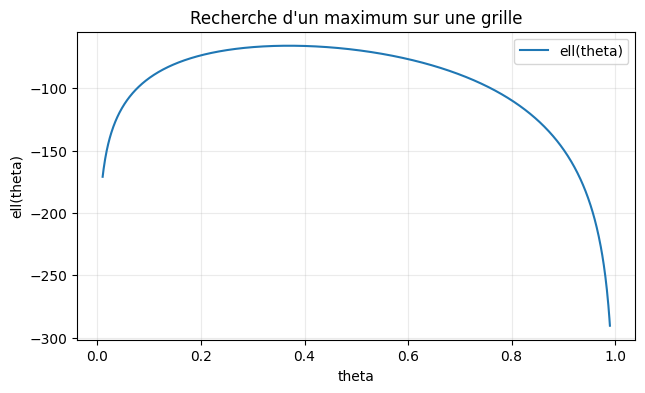

In [16]:
plt.figure(figsize=(7.2, 4))
plt.plot(theta, ell, label="ell(theta)")
plt.xlabel("theta")
plt.ylabel("ell(theta)")
plt.title("Recherche d'un maximum sur une grille")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

#### Visualisation (b) — Superposition de `ell` et `ell2`

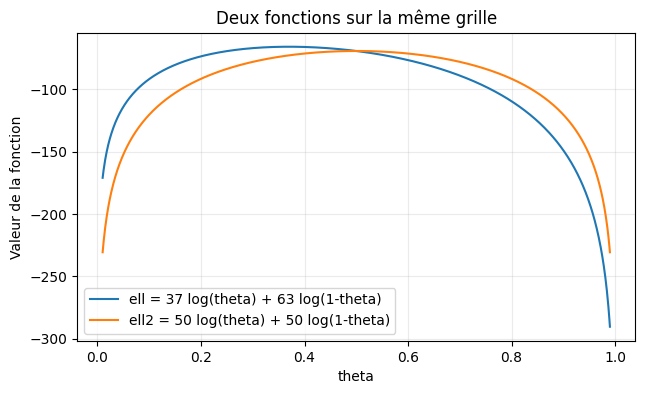

In [17]:
ell2 = 50*np.log(theta) + 50*np.log(1-theta)
plt.figure(figsize=(7.2, 4))
plt.plot(theta, ell, label="ell = 37 log(theta) + 63 log(1-theta)")
plt.plot(theta, ell2, label="ell2 = 50 log(theta) + 50 log(1-theta)")
plt.xlabel("theta")
plt.ylabel("Valeur de la fonction")
plt.title("Deux fonctions sur la même grille")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

La première courbe est maximale près de $0,37$ et la seconde près de $0,5$. Le graphique rend visible l'effet des coefficients de la fonction.

# 2. Une variable aléatoire comme fonction

## Exercice 3 — Deux dés : lois de $I$, $Z$ et du couple $(I,Z)$

L'univers $\Omega=\{1,\ldots,6\}^2$ comporte 36 issues équiprobables. On définit $I(i,j)=i$ et $Z(i,j)=\mathbf 1_{\{i=j\}}$ (1 si les deux dés donnent le même résultat, 0 sinon).

In [18]:
omega = np.array([(i, j) for i in range(1, 7)
                         for j in range(1, 7)])
print("Nombre d'issues :", len(omega))
print("Huit premières issues :\n", omega[:8])

Nombre d'issues : 36
Huit premières issues :
 [[1 1]
 [1 2]
 [1 3]
 [1 4]
 [1 5]
 [1 6]
 [2 1]
 [2 2]]


### 3.1 — Calculer les valeurs des deux variables aléatoires sur les 36 issues

In [19]:
I = omega[:, 0]
Z = (omega[:, 0] == omega[:, 1]).astype(int)
print("I, organisé en 6 lignes de 6 issues :\n", I.reshape(6, 6))
print("Z, organisé en 6 lignes de 6 issues :\n", Z.reshape(6, 6))

I, organisé en 6 lignes de 6 issues :
 [[1 1 1 1 1 1]
 [2 2 2 2 2 2]
 [3 3 3 3 3 3]
 [4 4 4 4 4 4]
 [5 5 5 5 5 5]
 [6 6 6 6 6 6]]
Z, organisé en 6 lignes de 6 issues :
 [[1 0 0 0 0 0]
 [0 1 0 0 0 0]
 [0 0 1 0 0 0]
 [0 0 0 1 0 0]
 [0 0 0 0 1 0]
 [0 0 0 0 0 1]]


L’expression `omega[:,0]` extrait les valeurs du premier dé. La comparaison des deux colonnes renvoie un tableau de booléens ; `astype(int)` transforme `True` en 1 et `False` en 0.

### 3.2 — Ensembles des valeurs $I(\Omega)$ et $Z(\Omega)$

In [20]:
val_I = np.unique(I)
val_Z = np.unique(Z)
print("I(Omega) =", val_I)
print("Z(Omega) =", val_Z)

I(Omega) = [1 2 3 4 5 6]
Z(Omega) = [0 1]


### 3.3 — Fonctions de masse de I et Z

In [21]:
val_I, effectifs_I = np.unique(I, return_counts=True)
val_Z, effectifs_Z = np.unique(Z, return_counts=True)
p_I = effectifs_I / len(omega)
p_Z = effectifs_Z / len(omega)
print("a   effectif   p_I(a)")
for a, n, p in zip(val_I, effectifs_I, p_I):
    print(f"{a:1d}       {n:2d}      {p:.6f}")
print("\nz   effectif   p_Z(z)")
for z, n, p in zip(val_Z, effectifs_Z, p_Z):
    print(f"{z:1d}       {n:2d}      {p:.6f}")
print("\nSommes des masses :", p_I.sum(), p_Z.sum())

a   effectif   p_I(a)
1        6      0.166667
2        6      0.166667
3        6      0.166667
4        6      0.166667
5        6      0.166667
6        6      0.166667

z   effectif   p_Z(z)
0       30      0.833333
1        6      0.166667

Sommes des masses : 0.9999999999999999 1.0


Ainsi $I$ est uniforme sur $\{1,\ldots,6\}$, avec $\mathbb P(I=a)=1/6$. Pour $Z$, on compte 6 doubles parmi 36 issues : $\mathbb P(Z=1)=1/6$ et $\mathbb P(Z=0)=5/6$.

### 3.4 — Graphiques des fonctions de masse avec `plt.stem`

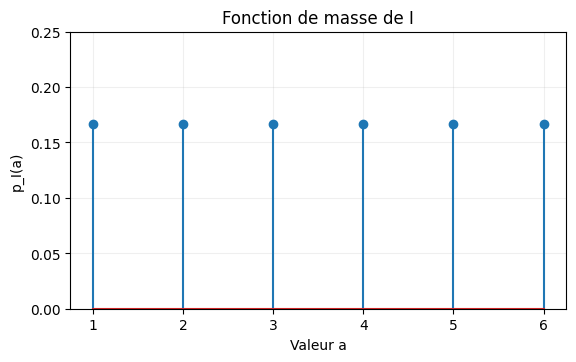

In [22]:
plt.figure(figsize=(6.4, 3.6))
plt.stem(val_I, p_I)
plt.xticks(val_I)
plt.ylim(0, 0.25)
plt.xlabel("Valeur a")
plt.ylabel("p_I(a)")
plt.title("Fonction de masse de I")
plt.grid(alpha=0.2)
plt.show()

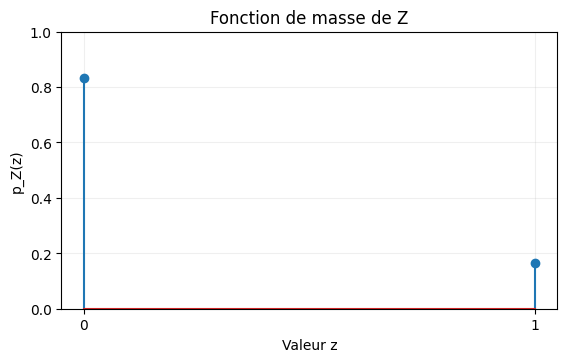

In [23]:
plt.figure(figsize=(6.4, 3.6))
plt.stem(val_Z, p_Z)
plt.xticks(val_Z)
plt.ylim(0, 1)
plt.xlabel("Valeur z")
plt.ylabel("p_Z(z)")
plt.title("Fonction de masse de Z")
plt.grid(alpha=0.2)
plt.show()

### 3.5 — Fonction de masse jointe du couple (I, Z)

In [24]:
p_jointe = np.zeros((6, 2))
for a in val_I:
    for z in val_Z:
        masque_az = (I == a) & (Z == z)
        p_jointe[a-1, z] = np.sum(masque_az) / len(omega)

print("Lignes : a=1,...,6 ; colonnes : z=0,1")
print(p_jointe)
print("Somme des 12 cases :", p_jointe.sum())

Lignes : a=1,...,6 ; colonnes : z=0,1
[[0.13888889 0.02777778]
 [0.13888889 0.02777778]
 [0.13888889 0.02777778]
 [0.13888889 0.02777778]
 [0.13888889 0.02777778]
 [0.13888889 0.02777778]]
Somme des 12 cases : 1.0


Pour un $a$ fixé, il existe une seule issue $(a,a)$ donnant $Z=1$ et cinq issues $(a,j)$ avec $j\neq a$ donnant $Z=0$. Chaque ligne du tableau joint vaut donc $(5/36,\,1/36)$. Le code utilise une double boucle uniquement pour remplir les **12 cases** ; le comptage des issues se fait par masques booléens.

### 3.6 — Visualiser la loi jointe par une carte de chaleur

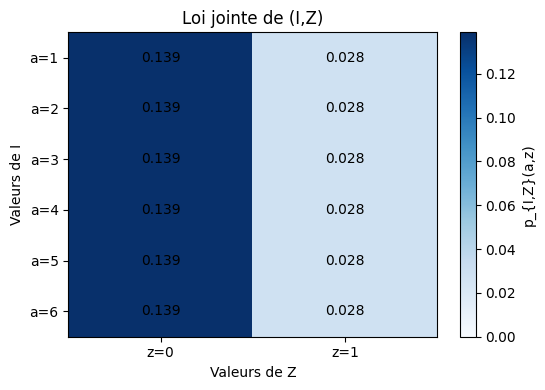

In [25]:
plt.figure(figsize=(5.6, 4))
im = plt.imshow(p_jointe, aspect="auto", cmap="Blues", vmin=0)
plt.colorbar(im, label="p_{I,Z}(a,z)")
plt.xticks([0,1], ["z=0", "z=1"])
plt.yticks(np.arange(6), [f"a={a}" for a in val_I])
plt.xlabel("Valeurs de Z")
plt.ylabel("Valeurs de I")
plt.title("Loi jointe de (I,Z)")
for row in range(6):
    for col in range(2):
        plt.text(col, row, f"{p_jointe[row,col]:.3f}",
                 ha="center", va="center", color="black")
plt.tight_layout()
plt.show()

### 3.7 — Retrouver les lois marginales à partir de la loi jointe

In [26]:
p_I_marg = np.sum(p_jointe, axis=1)  # somme des colonnes de chaque ligne
p_Z_marg = np.sum(p_jointe, axis=0)  # somme des lignes de chaque colonne
print("Loi marginale de I :", p_I_marg)
print("Loi marginale de Z :", p_Z_marg)
print("Sommes des marginales :", p_I_marg.sum(), p_Z_marg.sum())
print("Mêmes lois que celles calculées à la question 3 ?",
      np.allclose(p_I_marg, p_I) and np.allclose(p_Z_marg, p_Z))

Loi marginale de I : [0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]
Loi marginale de Z : [0.83333333 0.16666667]
Sommes des marginales : 1.0000000000000002 1.0
Mêmes lois que celles calculées à la question 3 ? True


Les identités utilisées sont $p_I(a)=\sum_{z\in\{0,1\}}p_{I,Z}(a,z)$ (somme d'une **ligne**) et $p_Z(z)=\sum_{a=1}^{6}p_{I,Z}(a,z)$ (somme d'une **colonne**).

### 3.8 — Tester l’indépendance de I et Z

In [27]:
produit_marginales = np.outer(p_I_marg, p_Z_marg)
print("p_I(a) p_Z(z) =\n", produit_marginales)
print("p_jointe =\n", p_jointe)
print("Égalité dans toutes les cases ?",
      np.allclose(p_jointe, produit_marginales))

p_I(a) p_Z(z) =
 [[0.13888889 0.02777778]
 [0.13888889 0.02777778]
 [0.13888889 0.02777778]
 [0.13888889 0.02777778]
 [0.13888889 0.02777778]
 [0.13888889 0.02777778]]
p_jointe =
 [[0.13888889 0.02777778]
 [0.13888889 0.02777778]
 [0.13888889 0.02777778]
 [0.13888889 0.02777778]
 [0.13888889 0.02777778]
 [0.13888889 0.02777778]]
Égalité dans toutes les cases ? True


**Conclusion : $I$ et $Z$ sont indépendantes.** Pour tout $a$, $\mathbb P(I=a,Z=0)=5/36=(1/6)(5/6)$ et $\mathbb P(I=a,Z=1)=1/36=(1/6)(1/6)$. On peut être surpris puisque $Z$ dépend des deux dés ; cependant, connaître **le résultat du premier dé** ne change pas la probabilité d'obtenir un double.

# 3. Lois discrètes usuelles et fonctions de masse

## Exercice 4 — Choisir une loi et utiliser sa fonction de masse

### Identifier la loi dans les trois situations

**a)** Si $Y$ vaut 1 pour une pièce défectueuse et 0 sinon, $Y(\Omega)=\{0,1\}$ et $Y\sim\mathcal B(p)$ au sens de la **loi de Bernoulli** de paramètre $p$ (notation pouvant être aussi $\mathrm{Bernoulli}(p)$).

**b)** Si $Y$ compte le nombre de pièces défectueuses parmi 20 contrôles indépendants de probabilité 0,05, $Y(\Omega)=\{0,1,\ldots,20\}$ et $Y\sim\mathcal B(20,0.05)$ (binomiale).

**c)** Si $Y$ est le rang du premier succès d'essais indépendants de probabilité de succès $p$, $Y(\Omega)=\{1,2,3,\ldots\}$ et $Y\sim\mathcal G(p)$ (géométrique), de fonction de masse $\mathbb P(Y=k)=(1-p)^{k-1}p$ pour $k\geq1$.

### 4.1 — Fonction de masse de $X\sim\mathcal B(20,0.05)$

k = [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20]
p_X(k) = [3.58486e-01 3.77354e-01 1.88677e-01 5.95820e-02 1.33280e-02 2.24500e-03
 2.95000e-04 3.10000e-05 3.00000e-06 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00]
Somme des probabilités : 1.0000000000000002


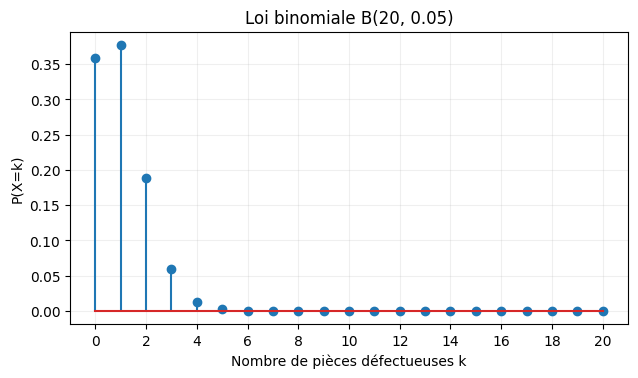

In [28]:
n, p = 20, 0.05
k = np.arange(n+1)
p_X = stats.binom.pmf(k, n=n, p=p)
print("k =", k)
print("p_X(k) =", np.round(p_X, 6))
print("Somme des probabilités :", p_X.sum())
plt.figure(figsize=(7.2, 3.8))
plt.stem(k, p_X)
plt.xticks(np.arange(0, 21, 2))
plt.xlabel("Nombre de pièces défectueuses k")
plt.ylabel("P(X=k)")
plt.title("Loi binomiale B(20, 0.05)")
plt.grid(alpha=0.2)
plt.show()

### 4.2 — Calculer $\mathbb P(X=0)$, $\mathbb P(X\le 2)$ et $\mathbb P(X\ge1)$

In [29]:
proba_X0 = p_X[0]
proba_Xle2 = np.sum(p_X[:3])
proba_Xge1 = 1 - p_X[0]
print(f"P(X=0)  = {proba_X0:.8f}")
print(f"P(X<=2) = {proba_Xle2:.8f}")
print(f"P(X>=1) = {proba_Xge1:.8f}")
print("Vérification SciPy :", stats.binom.cdf(2, n, p),
      stats.binom.sf(0, n, p))

P(X=0)  = 0.35848592
P(X<=2) = 0.92451633
P(X>=1) = 0.64151408
Vérification SciPy : 0.9245163262115037 0.6415140775914578


Il faut additionner les masses correspondant aux valeurs autorisées. Pour « au moins une pièce défectueuse », l'événement contraire $\{X=0\}$ donne $\mathbb P(X\ge1)=1-\mathbb P(X=0)$.

### 4.3 — Simuler 10 000 observations et comparer fréquences / masses

Cinq premières observations : [0 1 1 1 0]
Somme des fréquences empiriques : 1.0
P_emp(X=0) = 0.3536
P_theo(X=0) = 0.3585


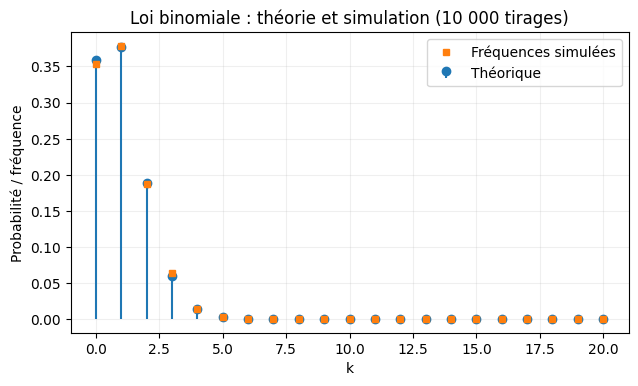

In [30]:
x_sim = rng.binomial(n=n, p=p, size=10_000)
frequences_X = np.bincount(x_sim, minlength=n+1) / len(x_sim)
print("Cinq premières observations :", x_sim[:5])
print("Somme des fréquences empiriques :", frequences_X.sum())
print("P_emp(X=0) =", round(frequences_X[0], 4))
print("P_theo(X=0) =", round(proba_X0, 4))
plt.figure(figsize=(7.2, 3.9))
plt.stem(k, p_X, linefmt="C0-", markerfmt="C0o", basefmt=" ",
         label="Théorique")
plt.plot(k, frequences_X, "C1s", label="Fréquences simulées", markersize=4)
plt.xlabel("k")
plt.ylabel("Probabilité / fréquence")
plt.title("Loi binomiale : théorie et simulation (10 000 tirages)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

Les fréquences simulées sont proches des probabilités théoriques, mais pas exactement égales. Elles varient avec les tirages ; la graine fixée rend seulement cette réalisation reproductible.

### Transformation : $V=\min(X,2)$

**Question 1.** Les seules valeurs possibles de $V$ sont $\{0,1,2\}$. Les événements correspondants sont
$$\{V=0\}=\{X=0\},\qquad \{V=1\}=\{X=1\},\qquad \{V=2\}=\{X\ge2\}.$$

**Question 2 — Fonction de masse de V.**

In [31]:
val_V = np.array([0, 1, 2])
p_V = np.array([p_X[0], p_X[1], np.sum(p_X[2:])])
print("Valeurs possibles de V :", val_V)
print("p_V =", np.round(p_V, 7))
print("Somme :", p_V.sum())

Valeurs possibles de V : [0 1 2]
p_V = [0.3584859 0.3773536 0.2641605]
Somme : 1.0000000000000002


Attention : $\{V=2\}$ regroupe **toutes** les issues où $X\ge 2$ (pas uniquement $X=2$).

**Question 3 — Transformation des simulations.**

Fréquences empiriques de V : [0.3536 0.3782 0.2682]
Probabilités théoriques de V : [0.35848592 0.3773536  0.26416048]


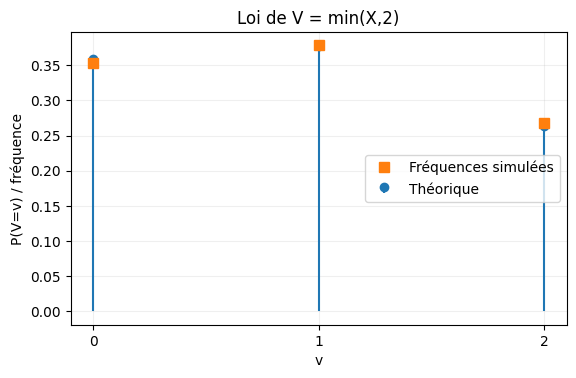

In [32]:
v_sim = np.minimum(x_sim, 2)
frequences_V = np.bincount(v_sim, minlength=3) / len(v_sim)
print("Fréquences empiriques de V :", frequences_V)
print("Probabilités théoriques de V :", p_V)
plt.figure(figsize=(6.4, 3.8))
plt.stem(val_V, p_V, linefmt="C0-", markerfmt="C0o", basefmt=" ",
         label="Théorique")
plt.plot(val_V, frequences_V, "C1s", markersize=7,
         label="Fréquences simulées")
plt.xticks(val_V)
plt.xlabel("v")
plt.ylabel("P(V=v) / fréquence")
plt.title("Loi de V = min(X,2)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# 4. Lois à densité

## Exercice 5 — Densité, simulation et transformation

Dans toute cette partie, $U\sim\mathcal U([0,1])$ et $T\sim\mathcal E(0.5)$. La loi exponentielle est paramétrée par son **taux** $\lambda=0.5$, donc par une **échelle** `scale=1/0.5=2` dans SciPy.

### 5.1 — Superposer les densités uniforme et exponentielle

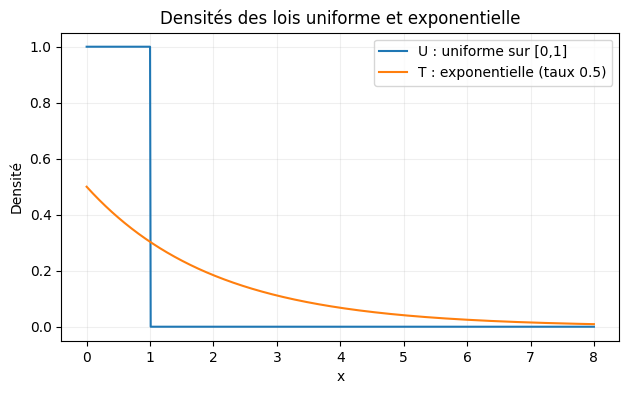

In [33]:
grille = np.linspace(0, 8, 801)
f_U = stats.uniform.pdf(grille, loc=0, scale=1)
f_T = stats.expon.pdf(grille, scale=2)
plt.figure(figsize=(7.2, 4))
plt.plot(grille, f_U, label="U : uniforme sur [0,1]")
plt.plot(grille, f_T, label="T : exponentielle (taux 0.5)")
plt.xlabel("x")
plt.ylabel("Densité")
plt.title("Densités des lois uniforme et exponentielle")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

La densité uniforme vaut 1 sur $[0,1]$ et 0 ailleurs. La densité exponentielle vaut $f_T(t)=0.5e^{-t/2}$ pour $t\ge0$ (et 0 sinon). La **hauteur d'une densité n'est pas une probabilité** : une probabilité est obtenue en intégrant sur un intervalle.

### 5.2 — Vérifier par intégration que chaque densité a une aire totale égale à 1

In [34]:
aire_U, erreur_U = quad(lambda v: stats.uniform.pdf(v, loc=0, scale=1),
                            0, 1)
aire_T, erreur_T = quad(lambda v: stats.expon.pdf(v, scale=2),
                            0, np.inf)
print(f"Intégrale de f_U sur [0,1] : {aire_U:.10f}; erreur estimée : {erreur_U:.2e}")
print(f"Intégrale de f_T sur [0,+inf[ : {aire_T:.10f}; erreur estimée : {erreur_T:.2e}")

Intégrale de f_U sur [0,1] : 1.0000000000; erreur estimée : 1.11e-14
Intégrale de f_T sur [0,+inf[ : 1.0000000000; erreur estimée : 3.58e-11


Les valeurs retournées par `quad` sont `(valeur de l’intégrale, estimation de l’erreur numérique)`. Pour une borne infinie, on écrit `np.inf`.

### 5.3 — Calculer $\mathbb P(0.4\le U\le 0.8)$ et $\mathbb P(T\ge3)$

In [35]:
p_U_intervalle, _ = quad(lambda v: stats.uniform.pdf(v, loc=0, scale=1),
                             0.4, 0.8)
p_T_ge3, _ = quad(lambda v: stats.expon.pdf(v, scale=2),
                  3, np.inf)
print(f"P(0.4 <= U <= 0.8) = {p_U_intervalle:.8f}")
print(f"P(T >= 3)         = {p_T_ge3:.8f}")
print("Vérification analytique pour T : exp(-0.5*3) =", np.exp(-1.5))

P(0.4 <= U <= 0.8) = 0.40000000
P(T >= 3)         = 0.22313016
Vérification analytique pour T : exp(-0.5*3) = 0.22313016014842982


La loi uniforme donne la longueur de l'intervalle, soit $0.8-0.4=0.4$. Pour l'exponentielle, $\mathbb P(T\ge3)=e^{-0.5\times 3}=e^{-1.5}$.

### 5.4 — Simuler U et T, histogramme normalisé et fréquence empirique

P(T>=3) théorique : 0.22313
Fréquence simulée : 0.219


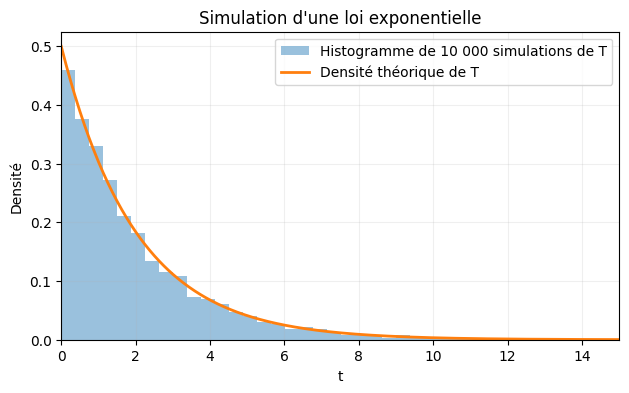

In [36]:
u_sim = rng.uniform(0, 1, size=10_000)
t_sim = rng.exponential(scale=2, size=10_000)
frequence_T_ge3 = np.mean(t_sim >= 3)
print("P(T>=3) théorique :", round(p_T_ge3, 6))
print("Fréquence simulée :", round(frequence_T_ge3, 6))
plt.figure(figsize=(7.2, 4))
plt.hist(t_sim, bins=45, density=True, alpha=0.45,
         label="Histogramme de 10 000 simulations de T")
x_dens = np.linspace(0, 15, 600)
plt.plot(x_dens, stats.expon.pdf(x_dens, scale=2), linewidth=2,
         label="Densité théorique de T")
plt.xlim(0, 15)
plt.xlabel("t")
plt.ylabel("Densité")
plt.title("Simulation d'une loi exponentielle")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

`density=True` normalise **l’aire totale** des barres à 1 ; il ne force pas leur somme à 1. La fréquence de l’événement `{T >= 3}` est proche de sa probabilité théorique.

### 5.5 — Loi de $V=-2\ln(1-U)$

Pour $t\ge0$, on transforme l'événement :

\begin{align*}
\{V\ge t\}
&=\{-2\ln(1-U)\ge t\}\\
&=\{\ln(1-U)\le -t/2\}\\
&=\{1-U\le e^{-t/2}\}\\
&=\{U\ge 1-e^{-t/2}\}.
\end{align*}

Comme $U$ est uniforme sur $[0,1]$, on obtient
$$\boxed{\mathbb P(V\ge t)=e^{-t/2}\quad(t\ge0).}$$

De plus $V\ge0$ presque sûrement, donc **$V\sim\mathcal E(0.5)$**. On a utilisé $U<1$, qui est vrai presque sûrement sous la loi uniforme continue.

In [37]:
v_trans = -2 * np.log1p(-u_sim)
print("Premières valeurs transformées :", np.round(v_trans[:5], 4))
print("Vérification des bornes :", np.min(v_trans), np.max(v_trans))
print("Fréquence de V>=3 :", round(np.mean(v_trans >= 3), 6))
print("Probabilité théorique :", round(np.exp(-1.5), 6))

Premières valeurs transformées : [5.1124 3.2613 1.4474 2.4145 0.2368]
Vérification des bornes : 0.00038061230713436537 19.220614648453342
Fréquence de V>=3 : 0.2161
Probabilité théorique : 0.22313


La fonction `np.log1p(-u_sim)` calcule numériquement `log(1-u_sim)` avec davantage de précision lorsque `u_sim` est très proche de 0.

### 5.6 — Comparer simulation directe et méthode d’inversion

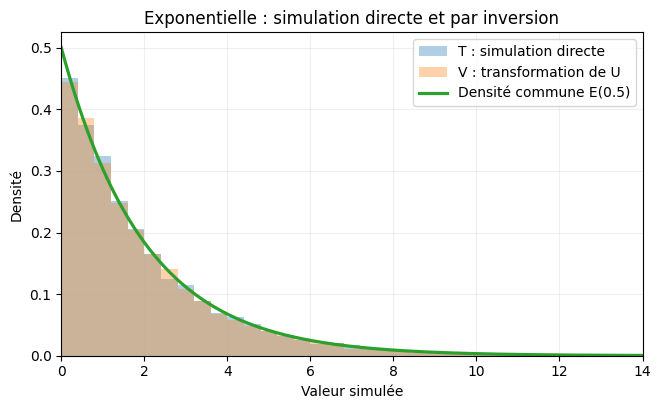

In [38]:
bornes = np.linspace(0, 18, 46)
plt.figure(figsize=(7.5, 4.2))
plt.hist(t_sim, bins=bornes, density=True, alpha=0.35,
         label="T : simulation directe")
plt.hist(v_trans, bins=bornes, density=True, alpha=0.35,
         label="V : transformation de U")
plt.plot(x_dens, stats.expon.pdf(x_dens, scale=2),
         linewidth=2.3, label="Densité commune E(0.5)")
plt.xlim(0, 14)
plt.xlabel("Valeur simulée")
plt.ylabel("Densité")
plt.title("Exponentielle : simulation directe et par inversion")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

**Conclusion :** les deux méthodes produisent des observations de même loi ; les histogrammes ne sont pas identiques, car ils proviennent d’échantillons simulés différents, mais ils se rapprochent tous les deux de la même densité.

## Proposition — Inversion d'une fonction de répartition

Pour une fonction de répartition $F$, on définit l’**inverse généralisée** par
$$F^{\leftarrow}(u)=\inf\{x\in\mathbb R:F(x)\ge u\},\qquad 0<u<1.$$
Si $W\sim\mathcal U([0,1])$, alors $F^{\leftarrow}(W)$ suit la loi de fonction de répartition $F$.

Dans le cas exponentiel de taux 0,5,
$$F(t)=1-e^{-t/2}\quad(t\ge0),\qquad F^{\leftarrow}(u)=-2\ln(1-u).$$

### Vérification numérique avec la commande SciPy `ppf`

In [39]:
u_test = np.array([0.10, 0.25, 0.50, 0.75, 0.90])
inv_calcul = -2 * np.log1p(-u_test)
inv_scipy = stats.expon.ppf(u_test, scale=2)
print("Niveaux u :", u_test)
print("Inverse analytique :", np.round(inv_calcul, 6))
print("SciPy : stats.expon.ppf :", np.round(inv_scipy, 6))
print("Coincidence numérique :", np.allclose(inv_calcul, inv_scipy))

Niveaux u : [0.1  0.25 0.5  0.75 0.9 ]
Inverse analytique : [0.210721 0.575364 1.386294 2.772589 4.60517 ]
SciPy : stats.expon.ppf : [0.210721 0.575364 1.386294 2.772589 4.60517 ]
Coincidence numérique : True


### Question facultative — Démonstration de la proposition

Posons $q(u)=F^{\leftarrow}(u)$ pour $u\in(0,1)$. La monotonie et la continuité à droite de $F$ permettent d'établir l'équivalence
$$q(u)\le x\quad\Longleftrightarrow\quad u\le F(x).$$

En effet, si $u\le F(x)$, l'ensemble $\{y:F(y)\ge u\}$ contient $x$, donc son infimum vérifie $q(u)\le x$. Réciproquement, si $q(u)\le x$, la définition de l'infimum et la continuité à droite de $F$ assurent $F(q(u))\ge u$ ; la croissance de $F$ donne alors $F(x)\ge u$.

Comme $W$ est uniforme sur $(0,1)$ (les bornes ayant une probabilité nulle), on obtient pour tout réel $x$ :
$$\mathbb P\bigl(F^{\leftarrow}(W)\le x\bigr)
=\mathbb P(W\le F(x))=F(x).$$
**La fonction de répartition de $F^{\leftarrow}(W)$ est donc bien $F$.** Cette démonstration ne suppose pas que $F$ soit strictement croissante ou continue : elle s'applique aussi aux lois discrètes.

# Pour la suite du module

Les outils `np.where`, `np.argsort`, `np.mean`, `np.std`, `np.quantile`, `@`, `np.linalg.solve`, `np.log`, `np.argmax`, `stats.*.pmf`, `stats.*.pdf`, `stats.*.cdf`, `stats.*.ppf` et les fonctions Matplotlib seront réutilisés pour la simulation, l'estimation de paramètres, la log-vraisemblance, les intervalles de confiance, les tests et la régression.

**Références de programmation :** [NumPy](https://numpy.org/doc/stable/), [SciPy](https://docs.scipy.org/doc/scipy/), [Matplotlib](https://matplotlib.org/stable/).